<a href="https://colab.research.google.com/github/anaghahegde326/BIS_LAB/blob/main/BIS_LAB2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Best Route: [2, 3, 4, 1, 0, 2]
Shortest Distance: 20.45


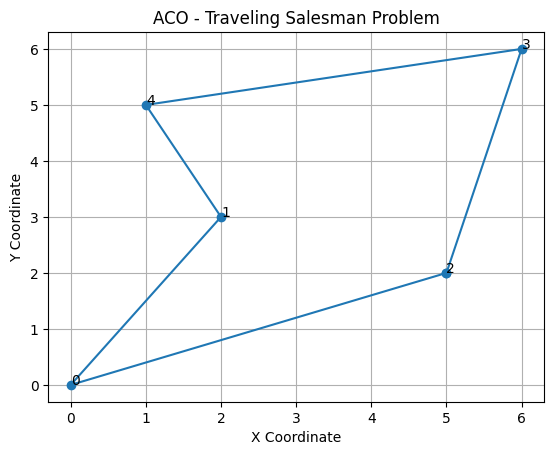

In [6]:

import random
import math
import matplotlib.pyplot as plt

# Coordinates of cities
cities = [(0, 0), (2, 3), (5, 2), (6, 6), (1, 5)]

n = len(cities)

# Calculate distances
distance = [[0] * n for i in range(n)]

for i in range(n):
    for j in range(n):
        x = cities[i][0] - cities[j][0]
        y = cities[i][1] - cities[j][1]
        distance[i][j] = math.sqrt(x*x + y*y)

# Initialize pheromones
pheromone = [[1] * n for i in range(n)]

# ACO parameters
ants = 5
iterations = 50
alpha = 1
beta = 2
rho = 0.5

best_route = None
best_distance = float('inf')

# ACO algorithm
for iteration in range(iterations):

    for ant in range(ants):

        # Select starting city
        route = [random.randint(0, n-1)]

        # Visit all cities
        while len(route) < n:
            current = route[-1]

            unvisited = [i for i in range(n) if i not in route]

            probabilities = []

            for city in unvisited:
                p = (pheromone[current][city] ** alpha) * \
                    ((1 / distance[current][city]) ** beta)
                probabilities.append(p)

            next_city = random.choices(
                unvisited, weights=probabilities
            )[0]

            route.append(next_city)

        # Return to starting city
        route.append(route[0])

        # Calculate total distance
        total = 0

        for i in range(n):
            total += distance[route[i]][route[i+1]]

        # Update best route
        if total < best_distance:
            best_distance = total
            best_route = route[:]

        # Update pheromones
        for i in range(n):
            a = route[i]
            b = route[i+1]

            pheromone[a][b] += 1 / total
            pheromone[b][a] += 1 / total

    # Evaporate pheromones
    for i in range(n):
        for j in range(n):
            pheromone[i][j] *= (1 - rho)

# Display result
print("Best Route:", best_route)
print("Shortest Distance:", round(best_distance, 2))

# Plot the best route
x = [cities[i][0] for i in best_route]
y = [cities[i][1] for i in best_route]

plt.plot(x, y, marker='o', linestyle='-')

# Label cities
for i in range(n):
    plt.text(cities[i][0], cities[i][1], str(i))

plt.title("ACO - Traveling Salesman Problem")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.grid(True)
plt.show()
